In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
empleados =pd.read_csv('C:\\Users\\super\\OneDrive\\Escritorio\\phyton\\empleados.csv')

In [4]:
empleados.head(10)
#con esto vemos los primeros 10 registros de los primeros 10 empleados

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2
5,32,No,Travel_Frequently,1005,Research & Development,2,2,Life Sciences,1,8,...,3,80,0,8,2,2,7,7,3,6
6,59,No,Travel_Rarely,1324,Research & Development,3,3,Medical,1,10,...,1,80,3,12,3,2,1,0,0,0
7,30,No,Travel_Rarely,1358,Research & Development,24,1,Life Sciences,1,11,...,2,80,1,1,2,3,1,0,0,0
8,38,No,Travel_Frequently,216,Research & Development,23,3,Life Sciences,1,12,...,2,80,0,10,2,3,9,7,1,8
9,36,No,Travel_Rarely,1299,Research & Development,27,3,Medical,1,13,...,2,80,2,17,3,2,7,7,7,7


In [5]:
empleados_seleccionados = empleados[['TotalWorkingYears', 'YearsAtCompany', 'Age']]
empleados_seleccionados_2 = empleados[['TotalWorkingYears', 'YearsAtCompany', 'YearsInCurrentRole']]
#seleccionamos las columnas que nos interesan para el analisis

Text(0.5, 0.92, 'Relación entre TotalWorkingYears, YearsAtCompany y Age / YearsInCurrentRole')

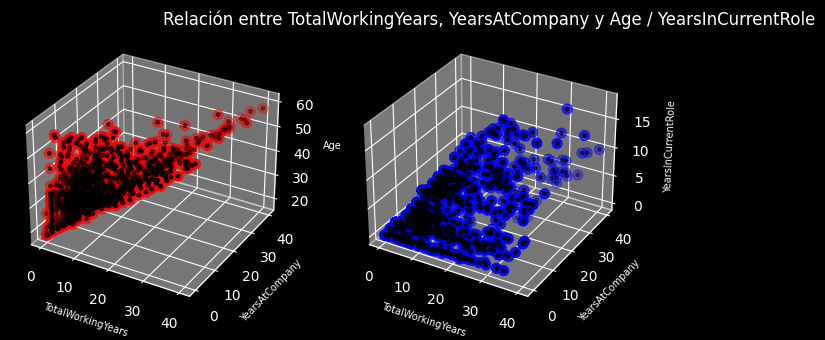

In [6]:
plt.style.use('dark_background')
fig = plt.figure(figsize=(8 ,8))
ax1 = fig.add_subplot(1, 2, 1 , projection='3d')
ax1.scatter(empleados_seleccionados['TotalWorkingYears'], empleados_seleccionados['YearsAtCompany'], empleados_seleccionados['Age'], c='r', marker='o', s=50)
ax1.scatter(empleados_seleccionados['TotalWorkingYears'], empleados_seleccionados['YearsAtCompany'], empleados_seleccionados['Age'], c='black', marker='o', s=7)
ax2 = fig.add_subplot(1, 2, 2 , projection='3d')
ax2.scatter(empleados_seleccionados_2['TotalWorkingYears'], empleados_seleccionados_2['YearsAtCompany'], empleados_seleccionados_2['YearsInCurrentRole'], c='b', marker='o', s=50)
ax2.scatter(empleados_seleccionados_2['TotalWorkingYears'], empleados_seleccionados_2['YearsAtCompany'], empleados_seleccionados_2['YearsInCurrentRole'], c='black', marker='o', s=7)

ax1.set_xlabel('TotalWorkingYears',fontsize=7)
ax1.set_ylabel('YearsAtCompany',fontsize=7)
ax1.set_zlabel('Age',fontsize=7)
ax2.set_xlabel('TotalWorkingYears',fontsize=7)
ax2.set_ylabel('YearsAtCompany',fontsize=7)
ax2.set_zlabel('YearsInCurrentRole',fontsize=7)
plt.title('Relación entre TotalWorkingYears, YearsAtCompany y Age / YearsInCurrentRole', fontsize=12)
#en el ax1podemos ver que las variables se relacionan positivamente, es decir, a mayor edad, mayor tiempo de trabajo y mayor tiempo en la empresa. En el ax2 podemos ver que a mayor tiempo de trabajo y mayor tiempo en la empresa,no necesariamente se relaciona con el tiempo en el rol actual, ya que hay empleados que llevan mucho tiempo en la empresa pero no llevan mucho tiempo en su rol actual, y viceversa. 


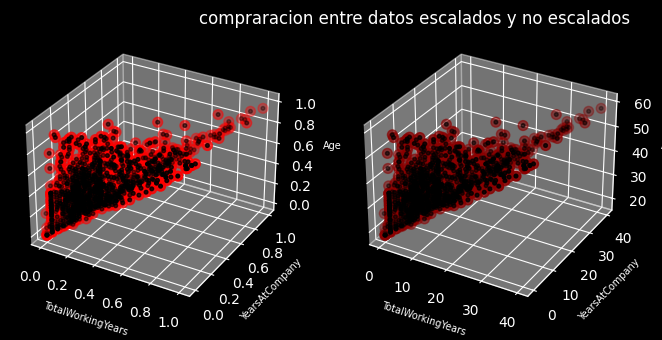

In [7]:
from sklearn import preprocessing
escalador = preprocessing.MinMaxScaler()
empleados_seleccionados_escalados = escalador.fit_transform(empleados_seleccionados)
empleados_seleccionados_2_escalados = escalador.fit_transform(empleados_seleccionados_2)
#si bien los datos usan escalas que podrian ser similares ,vale la pena escalarlos antes de usar KNN, ya que el algoritmo se basa en la distancia entre los puntos y si las escalas son muy diferentes, los resultados pueden ser sesgados. Por ejemplo, si una variable tiene un rango de 0 a 100 y otra variable tiene un rango de 0 a 1, la variable con el rango más grande dominará la distancia y afectará el resultado del algoritmo. Por eso es importante escalar los datos antes de usar KNN.
plt.style.use('dark_background')
fig = plt.figure(figsize=(8 ,8))
ax1 = fig.add_subplot(1, 2, 1, projection='3d')
ax1.scatter(empleados_seleccionados_escalados[:, 0], empleados_seleccionados_escalados[:, 1], empleados_seleccionados_escalados[:, 2], c='red', marker='o', s=50)
ax1.scatter(empleados_seleccionados_escalados[:, 0], empleados_seleccionados_escalados[:, 1], empleados_seleccionados_escalados[:, 2], c='black', marker='o', s=7)
ax2 = fig.add_subplot(1, 2, 2 , projection='3d')
ax2.scatter(empleados_seleccionados['TotalWorkingYears'], empleados_seleccionados['YearsAtCompany'], empleados_seleccionados['Age'], c='darkred', marker='o', s=50)
ax2.scatter(empleados_seleccionados['TotalWorkingYears'], empleados_seleccionados['YearsAtCompany'], empleados_seleccionados['Age'], c='black', marker='o', s=7)

ax1.set_xlabel('TotalWorkingYears',fontsize=7)
ax1.set_ylabel('YearsAtCompany',fontsize=7)
ax1.set_zlabel('Age',fontsize=7)
ax2.set_xlabel('TotalWorkingYears',fontsize=7)
ax2.set_ylabel('YearsAtCompany',fontsize=7)
ax2.set_zlabel('Age',fontsize=7)
plt.title('compraracion entre datos escalados y no escalados',loc='right', fontsize=12)
plt.show()
#si se aprecia que al escalar los datos, la relación entre las variables se mantiene, pero ahora todas las variables están en la misma escala, lo que permite una mejor comparación y análisis de los datos.

In [ ]:
empleados_seleccionados_escalados_faltantes = empleados_seleccionados_escalados.copy()

fila_edad = empleados_seleccionados_escalados_faltantes[:, 2]
valores_a_eliminar = int(fila_edad.shape[0] * 0.1)
np.random.seed(7)
valores_a_eliminar = np.random.choice(fila_edad.shape[0], size=valores_a_eliminar, replace=False)
empleados_seleccionados_escalados_faltantes[valores_a_eliminar, 2] = np.nan
#eliminamos el 10% de los datos de la columna Age para simular datos

In [9]:

print(empleados_seleccionados_escalados_faltantes)
print("\n")
print(empleados_seleccionados_escalados)

[[0.2        0.15       0.54761905]
 [0.25       0.25       0.73809524]
 [0.175      0.         0.45238095]
 ...
 [0.15       0.15              nan]
 [0.425      0.225      0.73809524]
 [0.15       0.1        0.38095238]]


[[0.2        0.15       0.54761905]
 [0.25       0.25       0.73809524]
 [0.175      0.         0.45238095]
 ...
 [0.15       0.15       0.21428571]
 [0.425      0.225      0.73809524]
 [0.15       0.1        0.38095238]]


In [11]:
from sklearn.impute import KNNImputer
imputer = KNNImputer(n_neighbors=5,weights='uniform')
imputer_uni = imputer.fit_transform(empleados_seleccionados_escalados_faltantes)

imputer= KNNImputer(n_neighbors=5,weights='distance')
imputer_dis = imputer.fit_transform(empleados_seleccionados_escalados_faltantes)
# la diferencia de distance y uniform es que distance pondera los vecinos más cercanos más que los más lejanos, mientras que uniform pondera a todos los vecinos por igual. En este caso, se espera que distance proporcione una mejor imputación de los valores faltantes, ya que los vecinos más cercanos son más similares a la observación con el valor faltante y, por lo tanto, son más informativos para la imputación.


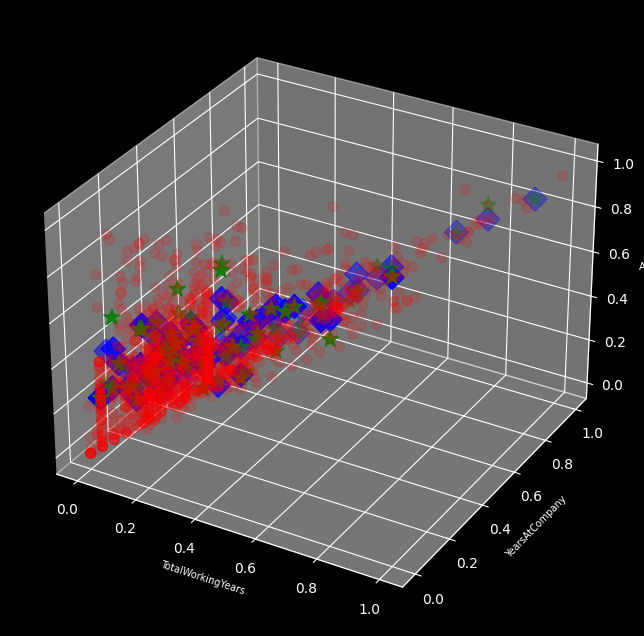

In [ ]:
fig = plt.figure(figsize=(8 ,8))
filtro = ~np.isnan(empleados_seleccionados_escalados_faltantes[:, 2])
ax1 = fig.add_subplot(1, 1, 1 , projection='3d')
ax1.scatter(empleados_seleccionados_escalados_faltantes.T[0][filtro], empleados_seleccionados_escalados_faltantes.T[1][filtro], empleados_seleccionados_escalados_faltantes.T[2][filtro],label='Datos Originales',alpha=0.15, c='r', marker='o', s=50)
ax1.scatter(imputer_dis.T[0][~filtro], imputer_dis.T[1][~filtro], imputer_dis.T[2][~filtro], label='Datos Faltantes', c='green', marker='*', s=150)
ax1.scatter(imputer_uni.T[0][~filtro], imputer_uni.T[1][~filtro], imputer_uni.T[2][~filtro], label='Imputación', c='blue', marker='D', s=150)
ax1.set_xlabel('TotalWorkingYears',fontsize=7)
ax1.set_ylabel('YearsAtCompany',fontsize=7)
ax1.set_zlabel('Age',fontsize=7)
plt.title('Imputación de valores faltantes con KNN', fontsize=12)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()
#podemos apreciar que la imputacion uniforme apila los datos mas hacia el centro (diamantes),auqnue ambas siguen la misma tendencia .la distribucion de de los pesos de los vecinos mas cercanos por la distancia (estrellas verdes) es mas dispersa, ya que los vecinos mas cercanos tienen un mayor peso en la imputacion, lo que permite una mejor estimacion de los valores faltantes.



